## 1. Exploratory Data Analysis

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_PATH = 'train.csv'
df = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())

Dataset shape: 699,960 rows x 26 columns


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


Class Imbalance (`is_fraud`), Missing Values, and Duplicate `id` Check

In [ ]:
df = pd.read_csv("train.csv")

fraud_counts = df['is_fraud'].value_counts()
fraud_rate = df['is_fraud'].value_counts(normalize=True) * 100

print(f"Count: Non-Fraud = {fraud_counts[0]}, Fraud = {fraud_counts[1]}")
print(f"Fraud Ratio: {fraud_rate[1]:.3f}%")

print("Missing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated(subset=['id']).sum())

Count: Non-Fraud = 688271, Fraud = 11689
Fraud Ratio: 1.670%
Missing values per column:
 Series([], dtype: int64)
Duplicate rows: 0


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,1,...,3D Secure,POS,Windows PC,False,False,False,False,False,False,0.0
699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,5,...,No Authentication,Online,iPhone,False,False,False,False,False,False,0.0
699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,4,...,Biometric,Online,Android Phone,False,False,True,False,False,False,0.0
699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,12,...,PIN,ATM,Windows PC,False,False,True,False,False,False,0.0


Quantitative Feature Mean/Median Comparison

In [27]:
num_cols = [
    'amount_usd', 'account_balance_usd', 'hours_since_last_txn',
    'txn_count_last_24h', 'distance_from_home_km', 'velocity_score',
    'merchant_risk_score', 'cvv_retry_count'
]

df.groupby('is_fraud')[num_cols].agg(['median', 'mean']).T

is_fraud                              0.0          1.0
amount_usd            median    27.210000    31.180000
                      mean      79.373189   110.504532
account_balance_usd   median  1382.740000  1396.000000
                      mean    2064.520948  2093.091944
hours_since_last_txn  median     4.730000     3.610000
                      mean       6.650530     5.644733
txn_count_last_24h    median     3.000000     4.000000
                      mean       2.972755     3.651638
distance_from_home_km median    10.220000    10.310000
                      mean      13.584810    13.750394
velocity_score        median    18.500000    26.600000
                      mean      18.785526    27.403704
merchant_risk_score   median    34.000000    45.900000
                      mean      35.011289    47.368449
cvv_retry_count       median     0.000000     0.000000
                      mean       0.077462     0.557105

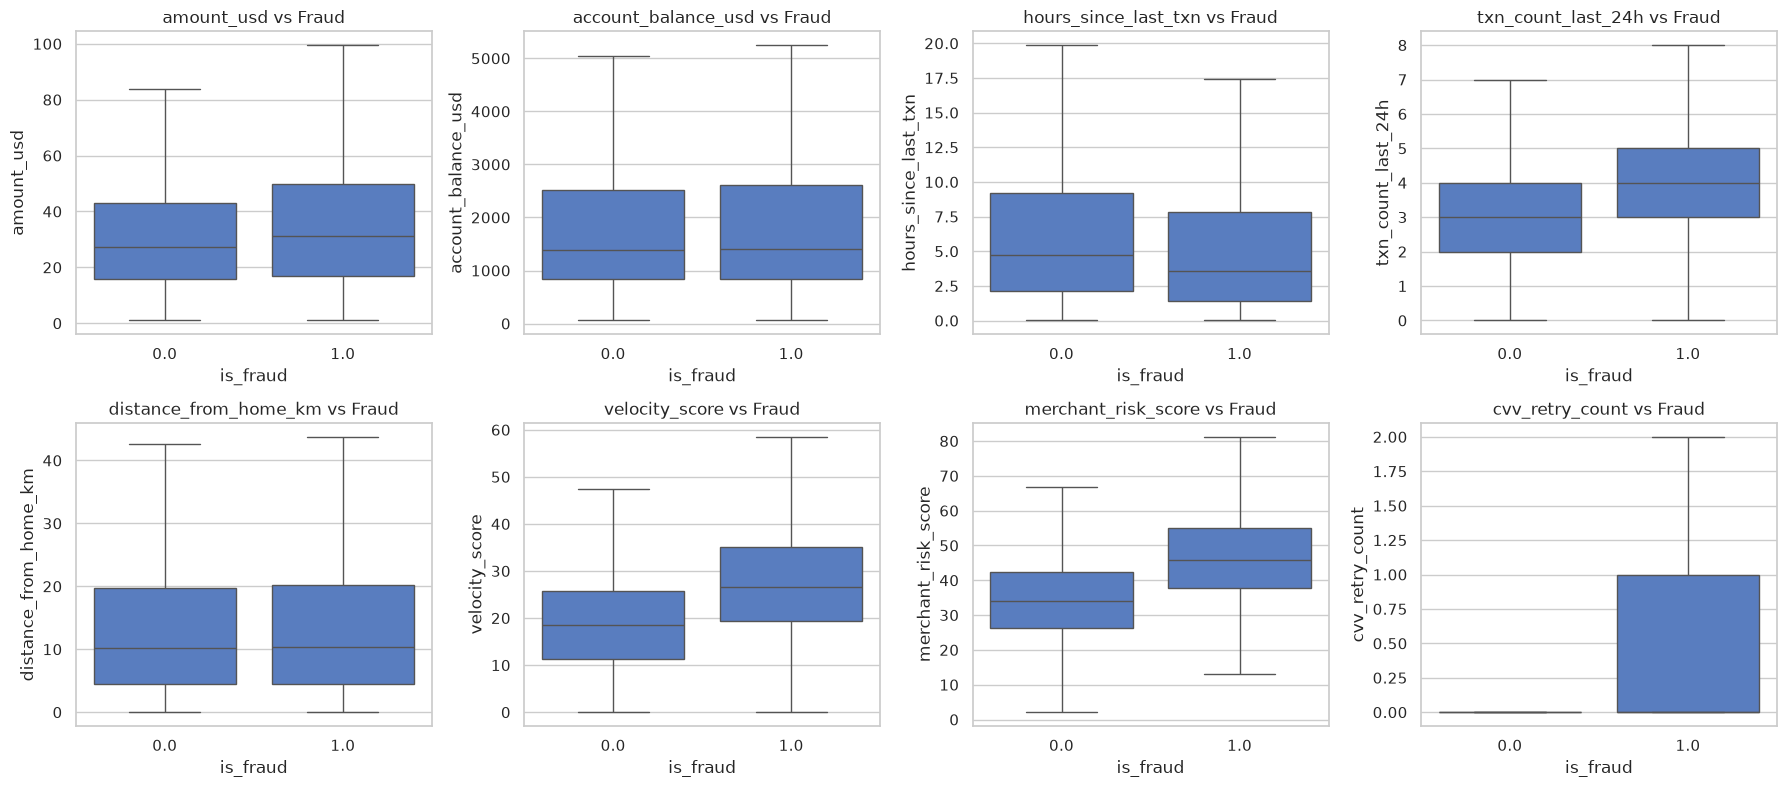

Fraud Rate by Time, Categorical Features & Binary Flag Risk Multiplier

Fraud Rate Over Time (`time_of_day_hour`, `day_of_week`)

In [ ]:
print('=' * 70)
print('FRAUD RATE ANALYSIS BY TIME')
print('=' * 70)

base_fraud_rate = df['is_fraud'].mean() * 100
print(f'Overall Fraud Rate: {base_fraud_rate:.4f}%\n')

# 1. By hour of day (time_of_day_hour)
hour_stats = df.groupby('time_of_day_hour')['is_fraud'].agg(
    total_txn='count',
    fraud_count='sum',
    fraud_rate='mean'
).reset_index()
hour_stats['fraud_rate_pct'] = hour_stats['fraud_rate'] * 100

print('--- Fraud Rate by Hour of Day (time_of_day_hour) ---')
display(hour_stats.round(4))

# 2. By day of week (day_of_week)
dow_stats = df.groupby('day_of_week')['is_fraud'].agg(
    total_txn='count',
    fraud_count='sum',
    fraud_rate='mean'
).reset_index()
dow_stats['fraud_rate_pct'] = dow_stats['fraud_rate'] * 100

day_order_map = {
    'Monday': 0, 'Tuesday': 1, 'Wednesday': 2, 'Thursday': 3,
    'Friday': 4, 'Saturday': 5, 'Sunday': 6,
    'Mon': 0, 'Tue': 1, 'Wed': 2, 'Thu': 3, 'Fri': 4, 'Sat': 5, 'Sun': 6
}
if dow_stats['day_of_week'].dtype == object and set(dow_stats['day_of_week']).issubset(set(day_order_map.keys())):
    dow_stats['sort_key'] = dow_stats['day_of_week'].map(day_order_map)
    dow_stats = dow_stats.sort_values('sort_key').drop(columns='sort_key')

print('\n--- Fraud Rate by Day of Week (day_of_week) ---')
display(dow_stats.round(4))

3A. FRAUD RATE ANALYSIS BY TIME
Overall Fraud Rate: 1.6700%

--- Fraud Rate by Hour of Day (time_of_day_hour) ---


,time_of_day_hour,total_txn,fraud_count,fraud_rate,fraud_rate_pct
0,0,25806,437.0,0.0169,1.6934
1,1,29912,431.0,0.0144,1.4409
2,2,26868,450.0,0.0167,1.6749
3,3,26967,472.0,0.0175,1.7503
4,4,27349,448.0,0.0164,1.6381
5,5,27412,488.0,0.0178,1.7802
6,6,27374,469.0,0.0171,1.7133
7,7,29779,495.0,0.0166,1.6622
8,8,27153,449.0,0.0165,1.6536
9,9,29056,513.0,0.0177,1.7656



--- Fraud Rate by Day of Week (day_of_week) ---


,day_of_week,total_txn,fraud_count,fraud_rate,fraud_rate_pct
0,0,100548,1591.0,0.0158,1.5823
1,1,102288,1694.0,0.0166,1.6561
2,2,101467,1697.0,0.0167,1.6725
3,3,97261,1595.0,0.0164,1.6399
4,4,102508,1718.0,0.0168,1.6760
5,5,95271,1600.0,0.0168,1.6794
6,6,100617,1794.0,0.0178,1.7830


Fraud Rate by Categorical Features (`merchant_category`, `card_type`, `auth_method`, `channel`, `device_type`)

In [25]:
print('=' * 70)
print('FRAUD RATE ANALYSIS BY CATEGORICAL FEATURES')
print('=' * 70)

cat_cols = ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

for col in cat_cols:
    cat_summary = df.groupby(col)['is_fraud'].agg(
        Total_Transactions='count',
        Fraud_Transactions='sum',
        Fraud_Rate_Pct=lambda x: x.mean() * 100
    ).sort_values(by='Fraud_Rate_Pct', ascending=False).reset_index()

    print(f'\n--- Summary by {col} ---')
    display(cat_summary.round(3))

FRAUD RATE ANALYSIS BY CATEGORICAL FEATURES

--- Summary by merchant_category ---


,merchant_category,Total_Transactions,Fraud_Transactions,Fraud_Rate_Pct
0,Gift Cards,9456,690.0,7.297
1,Crypto Exchange,5285,345.0,6.528
2,Gaming,23784,1311.0,5.512
3,Electronics,48693,1501.0,3.083
4,Streaming,47196,1061.0,2.248
5,Travel,28715,534.0,1.860
6,Utilities,42027,581.0,1.382
7,Healthcare,35889,462.0,1.287
8,Fuel,59880,741.0,1.237
9,Restaurants,101360,1159.0,1.143



--- Summary by card_type ---


,card_type,Total_Transactions,Fraud_Transactions,Fraud_Rate_Pct
0,Amex,45797,871.0,1.902
1,Visa,345001,5860.0,1.699
2,RuPay,37070,623.0,1.681
3,Mastercard,254857,4084.0,1.602
4,Discover,17235,251.0,1.456



--- Summary by auth_method ---


,auth_method,Total_Transactions,Fraud_Transactions,Fraud_Rate_Pct
0,No Authentication,67060,4322.0,6.445
1,3D Secure,210036,3098.0,1.475
2,OTP,175178,2464.0,1.407
3,PIN,154020,1337.0,0.868
4,Biometric,93666,468.0,0.500



--- Summary by channel ---


,channel,Total_Transactions,Fraud_Transactions,Fraud_Rate_Pct
0,Online,273939,4773.0,1.742
1,POS,206465,3428.0,1.660
2,In-App,83716,1367.0,1.633
3,ATM,30220,480.0,1.588
4,Contactless,105620,1641.0,1.554



--- Summary by device_type ---


,device_type,Total_Transactions,Fraud_Transactions,Fraud_Rate_Pct
0,POS Terminal,113237,1958.0,1.729
1,iPhone,164691,2836.0,1.722
2,Mac,33973,581.0,1.710
3,Tablet,27688,471.0,1.701
4,Smart Watch,21106,359.0,1.701
5,ATM Machine,20877,354.0,1.696
6,Windows PC,80934,1306.0,1.614
7,Android Phone,237454,3824.0,1.610


Risk Multiplier for the 6 Binary Flags

In [ ]:
print('=' * 70)
print('RISK MULTIPLIER FOR THE 6 BINARY FLAGS')
print('=' * 70)

binary_flags = [
    'is_foreign_transaction',
    'is_new_merchant',
    'used_vpn',
    'ip_country_mismatch',
    'billing_shipping_mismatch',
    'is_ai_generated_scam_attempt'
]

overall_fraud_rate = df['is_fraud'].mean()
risk_records = []

for flag in binary_flags:
    rate_when_1 = df.loc[df[flag] == 1, 'is_fraud'].mean()
    rate_when_0 = df.loc[df[flag] == 0, 'is_fraud'].mean()
    count_when_1 = (df[flag] == 1).sum()

    risk_multiplier = rate_when_1 / rate_when_0 if rate_when_0 > 0 else np.nan
    baseline_lift = rate_when_1 / overall_fraud_rate if overall_fraud_rate > 0 else np.nan

    risk_records.append({
        'Binary Flag': flag,
        'Count (Flag=1)': count_when_1,
        'Prevalence Flag=1 (%)': (count_when_1 / len(df)) * 100,
        'Fraud Rate (Flag=0) (%)': rate_when_0 * 100,
        'Fraud Rate (Flag=1) (%)': rate_when_1 * 100,
        'Risk Multiplier (Flag=1 / Flag=0)': risk_multiplier,
        'Lift vs Overall Avg': baseline_lift
    })

risk_df = pd.DataFrame(risk_records).sort_values(by='Risk Multiplier (Flag=1 / Flag=0)', ascending=False).round(3)
display(risk_df)



3C. RISK MULTIPLIER FOR THE 6 BINARY FLAGS


,Binary Flag,Count (Flag=1),Prevalence Flag=1 (%),Fraud Rate (Flag=0) (%),Fraud Rate (Flag=1) (%),Risk Multiplier (Flag=1 / Flag=0),Lift vs Overall Avg
3,ip_country_mismatch,11312,1.616,1.426,16.496,11.564,9.878
5,is_ai_generated_scam_attempt,2299,0.328,1.625,15.224,9.367,9.116
4,billing_shipping_mismatch,9054,1.294,1.522,12.989,8.536,7.778
0,is_foreign_transaction,12098,1.728,1.478,12.572,8.505,7.529
2,used_vpn,23665,3.381,1.499,6.550,4.369,3.922
1,is_new_merchant,106720,15.247,1.119,4.734,4.231,2.835


Analyze correlation

In [24]:
corr_cols = num_cols + binary_flags + ['is_fraud']

correlations = df[corr_cols].corr()['is_fraud'].sort_values(ascending=False)

correlations

is_fraud                        1.000000
cvv_retry_count                 0.212290
ip_country_mismatch             0.148284
merchant_risk_score             0.125391
is_foreign_transaction          0.112832
velocity_score                  0.101650
is_new_merchant                 0.101412
billing_shipping_mismatch       0.101115
used_vpn                        0.071235
is_ai_generated_scam_attempt    0.060719
txn_count_last_24h              0.058035
amount_usd                      0.019443
distance_from_home_km           0.001826
account_balance_usd             0.001077
hours_since_last_txn           -0.020490
Name: is_fraud, dtype: float64